# Chapter 2


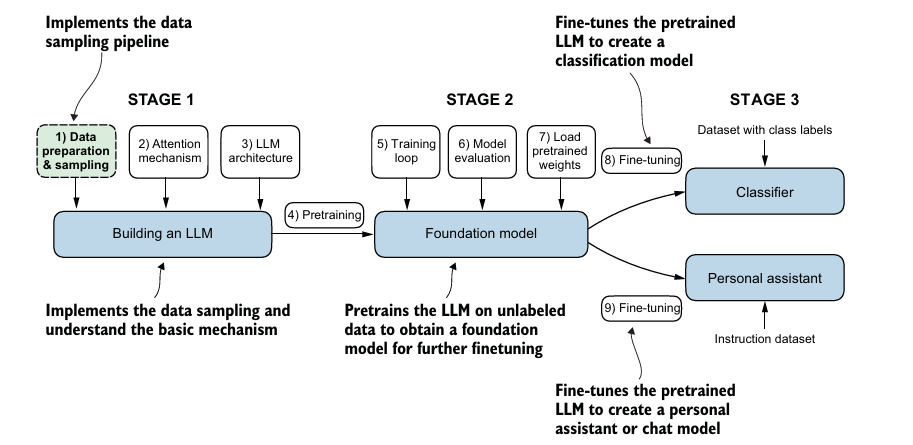

- Word are categorical hence we need to look for a way to convert it into vector "embeddings" which can then be used in our mathematical equations. 

- The concept of converting data into a vector format is often referred to as embedding.

- embeddings are specific to use cases. i.e embedding for videos will not be very fuctional for text. 

-  Sentence or paragraph embeddings are popular choices for retrieval-augmented generation. 

- word embeddings algorithms : word2vec (Word2Vec trained neural network architecture to generate word embeddings by pre
dicting the context of a word given the target word or vice versa. The main idea
behind Word2Vec is that words that appear in similar contexts tend to have similar
meanings.) , 

- Embeddings in LLM are learned so they are specific a task. 

### Tokenizing Text 

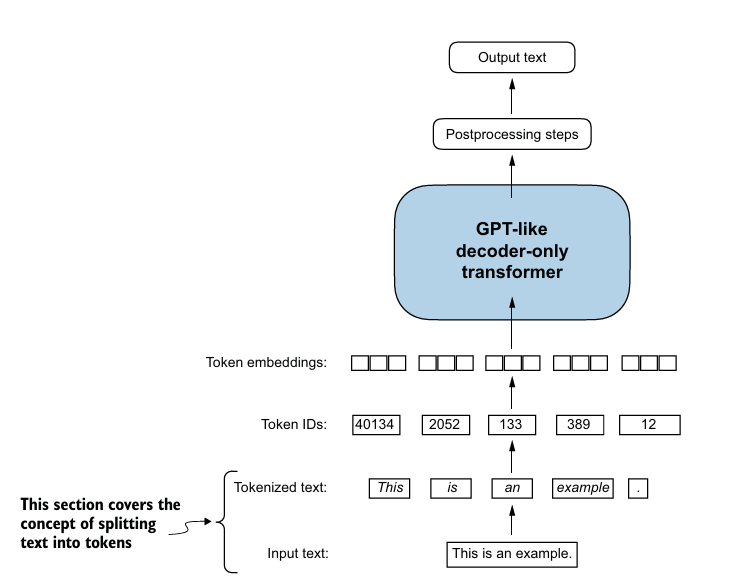

In [1]:
with open("the-verdict.txt", "r" , encoding="utf-8") as file:
    content = file.read()
print("The verdict has been read successfully.")
print("Total number of characters in the verdict:", len(content))
print(content[:99])

The verdict has been read successfully.
Total number of characters in the verdict: 20479
I HAD always thought Jack Gisburn rather a cheap genius--though a good fellow enough--so it was no 


In [2]:
# A little detour into Regular Expression 
import re 
text =  "Hello, world. This, is a test."
result = re.split(r'(\s)', text)
print(result)

['Hello,', ' ', 'world.', ' ', 'This,', ' ', 'is', ' ', 'a', ' ', 'test.']


In [3]:
#Modified for punctuations and so on
result = re.split(r'([,.]|\s)', text)
print(result)

['Hello', ',', '', ' ', 'world', '.', '', ' ', 'This', ',', '', ' ', 'is', ' ', 'a', ' ', 'test', '.', '']


In [4]:
# Now finally remove the whitespace 
result = [item for item in result if item.strip()]
print(result)

['Hello', ',', 'world', '.', 'This', ',', 'is', 'a', 'test', '.']


In [5]:
text =  "Hello, world. Is this-- a test?" 
result = re.split(r'([,.:;?_!"()\']|--|\s)' , text)
result = [item for item in result if item.strip()]
print(result)

['Hello', ',', 'world', '.', 'Is', 'this', '--', 'a', 'test', '?']


In [6]:
preprocessed =  re.split(r'([,.:;?_!"()\']|--|\s)' , content)
preprocessed = [item for item in preprocessed if item.strip()]
print("Total number of tokens in the verdict:", len(preprocessed))
print(preprocessed[:99])

Total number of tokens in the verdict: 4690
['I', 'HAD', 'always', 'thought', 'Jack', 'Gisburn', 'rather', 'a', 'cheap', 'genius', '--', 'though', 'a', 'good', 'fellow', 'enough', '--', 'so', 'it', 'was', 'no', 'great', 'surprise', 'to', 'me', 'to', 'hear', 'that', ',', 'in', 'the', 'height', 'of', 'his', 'glory', ',', 'he', 'had', 'dropped', 'his', 'painting', ',', 'married', 'a', 'rich', 'widow', ',', 'and', 'established', 'himself', 'in', 'a', 'villa', 'on', 'the', 'Riviera', '.', '(', 'Though', 'I', 'rather', 'thought', 'it', 'would', 'have', 'been', 'Rome', 'or', 'Florence', '.', ')', '"', 'The', 'height', 'of', 'his', 'glory', '"', '--', 'that', 'was', 'what', 'the', 'women', 'called', 'it', '.', 'I', 'can', 'hear', 'Mrs', '.', 'Gideon', 'Thwing', '--', 'his', 'last', 'Chicago', 'sitter']


### Convert tokens to IDs 

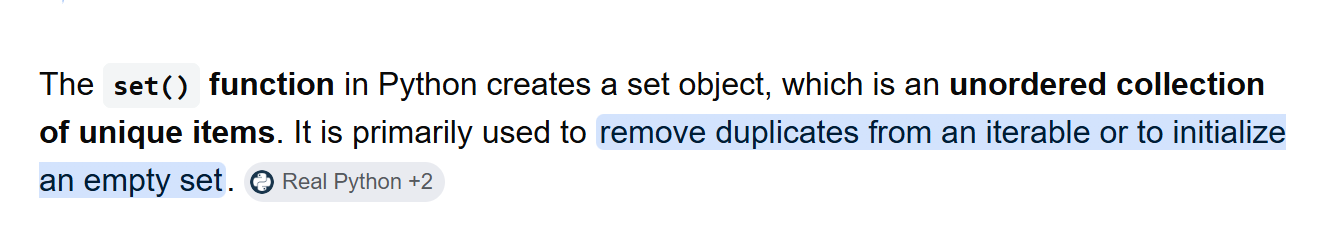

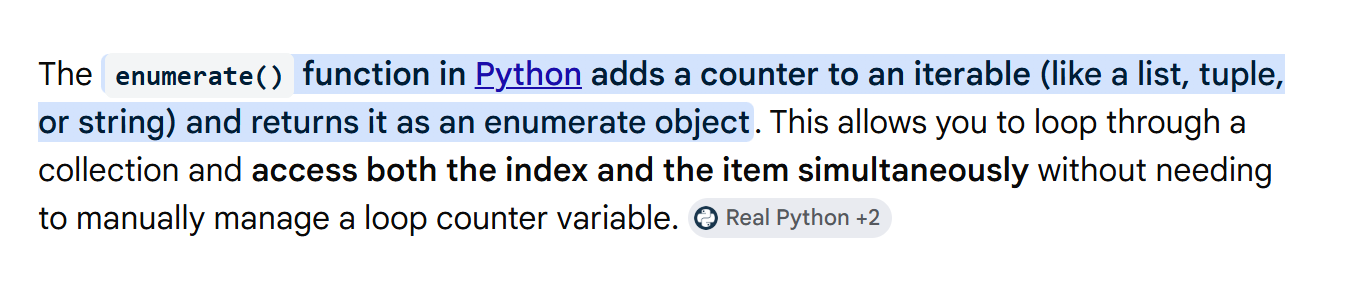

In [7]:
all_words = sorted(set(preprocessed))
vocab_size = len(all_words)
print(vocab_size)

1130


In [8]:
vocab = {token : index for index, token in enumerate(all_words)}
for i , item in enumerate(vocab.items()):
    print(item)
    if i >= 50 :
        break

('!', 0)
('"', 1)
("'", 2)
('(', 3)
(')', 4)
(',', 5)
('--', 6)
('.', 7)
(':', 8)
(';', 9)
('?', 10)
('A', 11)
('Ah', 12)
('Among', 13)
('And', 14)
('Are', 15)
('Arrt', 16)
('As', 17)
('At', 18)
('Be', 19)
('Begin', 20)
('Burlington', 21)
('But', 22)
('By', 23)
('Carlo', 24)
('Chicago', 25)
('Claude', 26)
('Come', 27)
('Croft', 28)
('Destroyed', 29)
('Devonshire', 30)
('Don', 31)
('Dubarry', 32)
('Emperors', 33)
('Florence', 34)
('For', 35)
('Gallery', 36)
('Gideon', 37)
('Gisburn', 38)
('Gisburns', 39)
('Grafton', 40)
('Greek', 41)
('Grindle', 42)
('Grindles', 43)
('HAD', 44)
('Had', 45)
('Hang', 46)
('Has', 47)
('He', 48)
('Her', 49)
('Hermia', 50)


In [9]:
class SimpleTokenizerv1: 
    def __init__(self, vocab): 
        self.str_to_int = vocab 
        self.int_to_str = {i:s for s,i in vocab.items()}
    def encode(self , text): 
        preprocessed =  re.split(r'([,.:;?_!"()\']|--|\s)' , text)
        preprocessed = [item for item in preprocessed if item.strip()]
        ids = [self.str_to_int[s] for s in preprocessed]
        return ids
    
    def decode(self , ids):
        text = " ".join([self.int_to_str[i] for i in ids])
        text =  re.sub(r'\s+([,.?!"()\'])', r'\1', text)
        return text


In [10]:
tokenizer = SimpleTokenizerv1(vocab) 
text =  """"It's the last he painted, you know," 
       Mrs. Gisburn said with pardonable pride."""
ids = tokenizer.encode(text)
ids = tokenizer.encode(text)
print(ids)

[1, 56, 2, 850, 988, 602, 533, 746, 5, 1126, 596, 5, 1, 67, 7, 38, 851, 1108, 754, 793, 7]


In [11]:
text = tokenizer.decode(ids)
print(text)

" It' s the last he painted, you know," Mrs. Gisburn said with pardonable pride.


In [12]:
all_tokens = sorted(list(set(preprocessed)))
all_tokens.extend(["<|endoftext|>", "<|unk|>"])
vocab = {item:integer for integer, item in enumerate(all_tokens)}
print(len(vocab.items()))

1132


In [13]:
for i, item in enumerate(list(vocab.items())[-5:]):
    print(item)

('younger', 1127)
('your', 1128)
('yourself', 1129)
('<|endoftext|>', 1130)
('<|unk|>', 1131)


In [14]:
class SimpleTokenizerV2: 
    def __init__(self, vocab): 
        self.str_to_int = vocab 
        self.int_to_str = {i:s for s,i in vocab.items()}
    def encode(self , text): 
        preprocessed =  re.split(r'([,.:;?_!"()\']|--|\s)' , text)
        preprocessed = [item for item in preprocessed if item.strip()]
        preprocessed = [item if item in self.str_to_int else "<|unk|>" for item in preprocessed]
        ids = [self.str_to_int[s] for s in preprocessed]
        return ids
    
    def decode(self , ids):
        text = " ".join([self.int_to_str[i] for i in ids])
        text =  re.sub(r'\s+([,.:;?!"()\'])', r'\1', text)
        return text


In [15]:
text1 = "Hello, do you like tea?"
text2 = "In the sunlit terraces of the palace."
text = " <|endoftext|> ".join((text1, text2))
print(text)

Hello, do you like tea? <|endoftext|> In the sunlit terraces of the palace.


In [16]:
tokenizer = SimpleTokenizerV2(vocab)
print(tokenizer.encode(text))

[1131, 5, 355, 1126, 628, 975, 10, 1130, 55, 988, 956, 984, 722, 988, 1131, 7]


In [17]:
print(tokenizer.decode(tokenizer.encode(text)))

<|unk|>, do you like tea? <|endoftext|> In the sunlit terraces of the <|unk|>.


### Byte pair encoding

In [18]:
!pip install tiktoken

In [47]:
from importlib.metadata import version
import tiktoken
print("tiktoken version:", version("tiktoken"))

tiktoken version: 0.13.0


In [48]:
tokenizer = tiktoken.get_encoding("gpt2")

In [49]:
text = (
    "Hello, do you like tea? <|endoftext|> In the sunlit terraces"
     "of someunknownPlace."
)
integers = tokenizer.encode(text, allowed_special={"<|endoftext|>"})
print(integers)

[15496, 11, 466, 345, 588, 8887, 30, 220, 50256, 554, 262, 4252, 18250, 8812, 2114, 1659, 617, 34680, 27271, 13]


In [22]:
strings = tokenizer.decode(integers)
print(strings)

Hello, do you like tea? <|endoftext|> In the sunlit terracesof someunknownPlace.


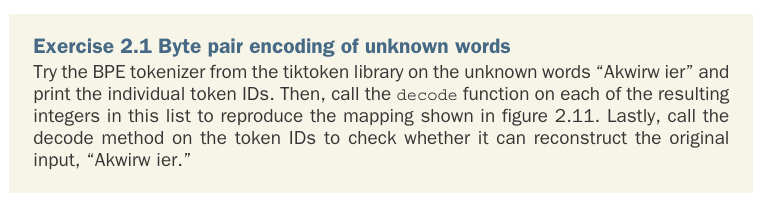

In [23]:
text = ("Akwirw ier")
integers = tokenizer.encode(text, allowed_special={"<|endoftext|>"})
print(integers)

[33901, 86, 343, 86, 220, 959]


In [37]:
strings = tokenizer.decode(integers)
print(strings)

Akwirw ier


### Data sampling with a sliding window

In [25]:
# need to create input-targetpairs for training 
with open("the-verdict.txt", "r" , encoding="utf-8") as file:
    content = file.read()

enc_text = tokenizer.encode(content)
print(len(enc_text))

5145


In [26]:
enc_sample = enc_text[50:]
print(enc_sample)

[290, 4920, 2241, 287, 257, 4489, 64, 319, 262, 34686, 41976, 13, 357, 10915, 314, 2138, 1807, 340, 561, 423, 587, 10598, 393, 28537, 2014, 198, 198, 1, 464, 6001, 286, 465, 13476, 1, 438, 5562, 373, 644, 262, 1466, 1444, 340, 13, 314, 460, 3285, 9074, 13, 46606, 536, 5469, 438, 14363, 938, 4842, 1650, 353, 438, 2934, 489, 3255, 465, 48422, 540, 450, 67, 3299, 13, 366, 5189, 1781, 340, 338, 1016, 284, 3758, 262, 1988, 286, 616, 4286, 705, 1014, 510, 26, 475, 314, 836, 470, 892, 286, 326, 11, 1770, 13, 8759, 2763, 438, 1169, 2994, 284, 943, 17034, 318, 477, 314, 892, 286, 526, 383, 1573, 11, 319, 9074, 13, 536, 5469, 338, 11914, 11, 33096, 663, 4808, 3808, 62, 355, 996, 484, 547, 12548, 287, 281, 13079, 410, 12523, 286, 22353, 13, 843, 340, 373, 407, 691, 262, 9074, 13, 536, 48819, 508, 25722, 276, 13, 11161, 407, 262, 40123, 18113, 544, 9325, 701, 11, 379, 262, 938, 402, 1617, 261, 12917, 905, 11, 5025, 502, 878, 402, 271, 10899, 338, 366, 31640, 12, 67, 20811, 1, 284, 910, 11, 351, 10

In [27]:
# we can create two variables. x and y 

context_size = 4 
x = enc_sample[:context_size]
y = enc_sample[1:context_size+1]
print(f"x: {x}")
print(f"y:       {y}")

x: [290, 4920, 2241, 287]
y:       [4920, 2241, 287, 257]


In [28]:
for i in range(1 , context_size + 1 ): 
    context = enc_sample[:i]
    desired = enc_sample[i]
    print(context , "------> " , desired)

[290] ------>  4920
[290, 4920] ------>  2241
[290, 4920, 2241] ------>  287
[290, 4920, 2241, 287] ------>  257


In [29]:
enc_sample[0]

290

In [36]:
for i in range(1 , context_size + 1 ): 
    context = enc_sample[:i]
    desired = enc_sample[i]
    print(tokenizer.decode(context), "------> " , tokenizer.decode([desired]))

 and ------>   established
 and established ------>   himself
 and established himself ------>   in
 and established himself in ------>   a


In [ ]:
import torch
from torch.utils.data  import Dataset, DataLoader

class GptDatasetv1(Dataset): 
  
  def __init__(self, content, tokenizer , max_length , stride ):
    self.input_ids = []
    self.target_ids = []

    tokenized = tokenizer.encode(content)

    for i in range(0, len(tokenized) - max_length, stride):
        input_chunk = tokenized[i:i+max_length]
        target_chunk = tokenized[i+1:i+max_length+1]

        self.input_ids.append(torch.tensor(input_chunk))
        self.target_ids.append(torch.tensor(target_chunk))

  def __len__(self):
        return len(self.input_ids) #check length of the dataset
    
  def __getitem__(self, idx):
        return self.input_ids[idx], self.target_ids[idx]
    

def create_dataloader(content , batch_size=4 , max_length=256 ,stride=128 , shuffle=True,
                      drop_last=True , num_workers=0):
    tokenizer = tiktoken.get_encoding("gpt2")
    dataset = GptDatasetv1(content, tokenizer , max_length , stride)
    dataloader = DataLoader(dataset, batch_size=batch_size, shuffle=shuffle,
                            drop_last=drop_last, num_workers=num_workers)
    
    return dataloader 

with open("the-verdict.txt", "r", encoding="utf-8") as f:
    content = f.read()

dataloader = create_dataloader(content , batch_size=1 , max_length=4 ,stride=1 , shuffle=False,
                 num_workers=0)

    

[tensor([[  40,  367, 2885, 1464]]), tensor([[ 367, 2885, 1464, 1807]])]


In [52]:
data_iter = iter(dataloader)
first_batch = next(data_iter)
print(first_batch)

[tensor([[  40,  367, 2885, 1464]]), tensor([[ 367, 2885, 1464, 1807]])]


In [53]:
second_batch = next(data_iter)
print(second_batch)

[tensor([[ 367, 2885, 1464, 1807]]), tensor([[2885, 1464, 1807, 3619]])]


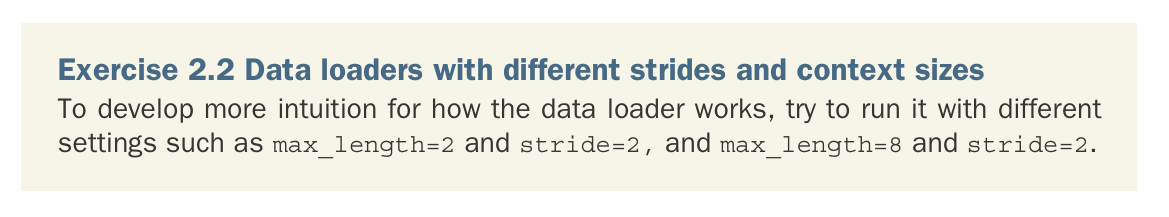

In [58]:
# max_length = 2 and stride = 2
dataloader = create_dataloader(
    content,
    batch_size=1,
    max_length=2,
    stride=2,
    shuffle=False,
    num_workers=0
)

data_iter = iter(dataloader)
first_batch = next(data_iter)

print(first_batch)

input_ids = first_batch[0][0].tolist()
target_ids = first_batch[1][0].tolist()

print("Input IDs as list:", input_ids)
print("Target IDs as list:", target_ids)

print(
    tokenizer.decode(input_ids),
    "------>",
    tokenizer.decode(target_ids)
)

[tensor([[ 40, 367]]), tensor([[ 367, 2885]])]
Input IDs as list: [40, 367]
Target IDs as list: [367, 2885]
I H ------>  HAD


In [60]:
# max length = 8 and stride = 2 
dataloader = create_dataloader(
    content,
    batch_size=4,
    max_length=8,
    stride=2,
    shuffle=False,
    num_workers=0
)

data_iter = iter(dataloader)
first_batch = next(data_iter)

print(first_batch)

input_ids = first_batch[0][0].tolist()
target_ids = first_batch[1][0].tolist()

print("Input IDs as list:", input_ids)
print("Target IDs as list:", target_ids)

print(
    tokenizer.decode(input_ids),
    "------>",
    tokenizer.decode(target_ids)
)

[tensor([[   40,   367,  2885,  1464,  1807,  3619,   402,   271],
        [ 2885,  1464,  1807,  3619,   402,   271, 10899,  2138],
        [ 1807,  3619,   402,   271, 10899,  2138,   257,  7026],
        [  402,   271, 10899,  2138,   257,  7026, 15632,   438]]), tensor([[  367,  2885,  1464,  1807,  3619,   402,   271, 10899],
        [ 1464,  1807,  3619,   402,   271, 10899,  2138,   257],
        [ 3619,   402,   271, 10899,  2138,   257,  7026, 15632],
        [  271, 10899,  2138,   257,  7026, 15632,   438,  2016]])]
Input IDs as list: [40, 367, 2885, 1464, 1807, 3619, 402, 271]
Target IDs as list: [367, 2885, 1464, 1807, 3619, 402, 271, 10899]
I HAD always thought Jack Gis ------>  HAD always thought Jack Gisburn


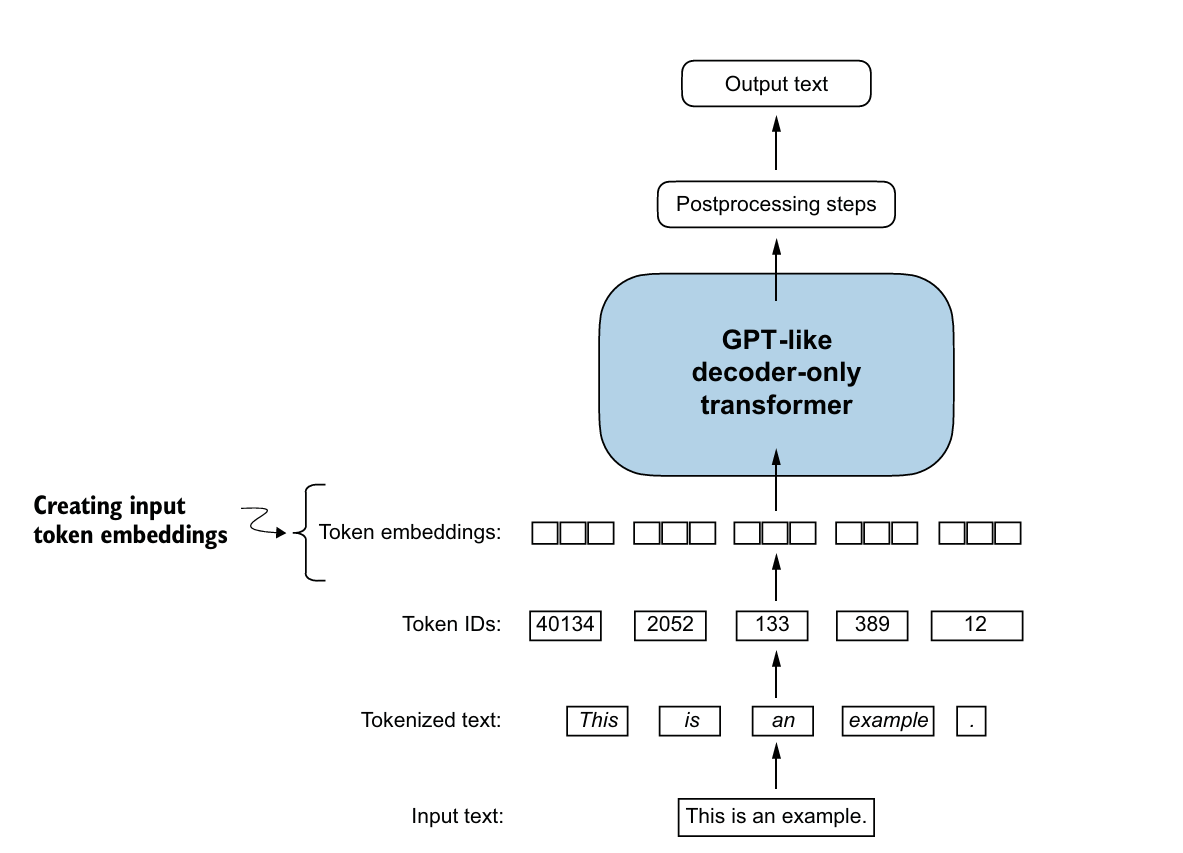

In [61]:
vocab_size = 6
output_dim = 3
torch.manual_seed(123)
embedding_layer = torch.nn.Embedding(vocab_size, output_dim)
print(embedding_layer.weight)

Parameter containing:
tensor([[ 0.3374, -0.1778, -0.1690],
        [ 0.9178,  1.5810,  1.3010],
        [ 1.2753, -0.2010, -0.1606],
        [-0.4015,  0.9666, -1.1481],
        [-1.1589,  0.3255, -0.6315],
        [-2.8400, -0.7849, -1.4096]], requires_grad=True)


In [62]:
print(embedding_layer(torch.tensor([3])))

tensor([[-0.4015,  0.9666, -1.1481]], grad_fn=<EmbeddingBackward0>)


In [64]:
input_ids = torch.tensor([2, 3, 5, 1])
print(embedding_layer(input_ids))

tensor([[ 1.2753, -0.2010, -0.1606],
        [-0.4015,  0.9666, -1.1481],
        [-2.8400, -0.7849, -1.4096],
        [ 0.9178,  1.5810,  1.3010]], grad_fn=<EmbeddingBackward0>)


- The embedding layer is like a look up table that assigns contionous values to token IDs so they can be used for calculations. 



- relative positional embeddings and absolute positional embeddings. Absolute positional
embeddings are directly associated with specific positions in a sequence. For each posi
tion in the input sequence, a unique embedding is added to the token’s embedding to
convey its exact location. For instance, the first token will have a specific positional
embedding, the second token another distinct embedding

In [65]:
vocab_size = 50257
output_dim = 256
token_embedding_layer = torch.nn.Embedding(vocab_size, output_dim)
max_length = 4
dataloader = create_dataloader(
    content, batch_size=8, max_length=max_length,
   stride=max_length, shuffle=False
)
data_iter = iter(dataloader)
inputs, targets = next(data_iter)
print("Token IDs:\n", inputs)
print("\nInputs shape:\n", inputs.shape)

Token IDs:
 tensor([[   40,   367,  2885,  1464],
        [ 1807,  3619,   402,   271],
        [10899,  2138,   257,  7026],
        [15632,   438,  2016,   257],
        [  922,  5891,  1576,   438],
        [  568,   340,   373,   645],
        [ 1049,  5975,   284,   502],
        [  284,  3285,   326,    11]])

Inputs shape:
 torch.Size([8, 4])


In [66]:
token_embeddings = token_embedding_layer(inputs)
print(token_embeddings.shape)

torch.Size([8, 4, 256])


In [67]:
context_length = max_length
pos_embedding_layer = torch.nn.Embedding(context_length, output_dim)
pos_embeddings = pos_embedding_layer(torch.arange(context_length))
print(pos_embeddings.shape)

torch.Size([4, 256])


In [68]:
input_embedding = token_embeddings + pos_embeddings
print(input_embedding.shape)


torch.Size([8, 4, 256])


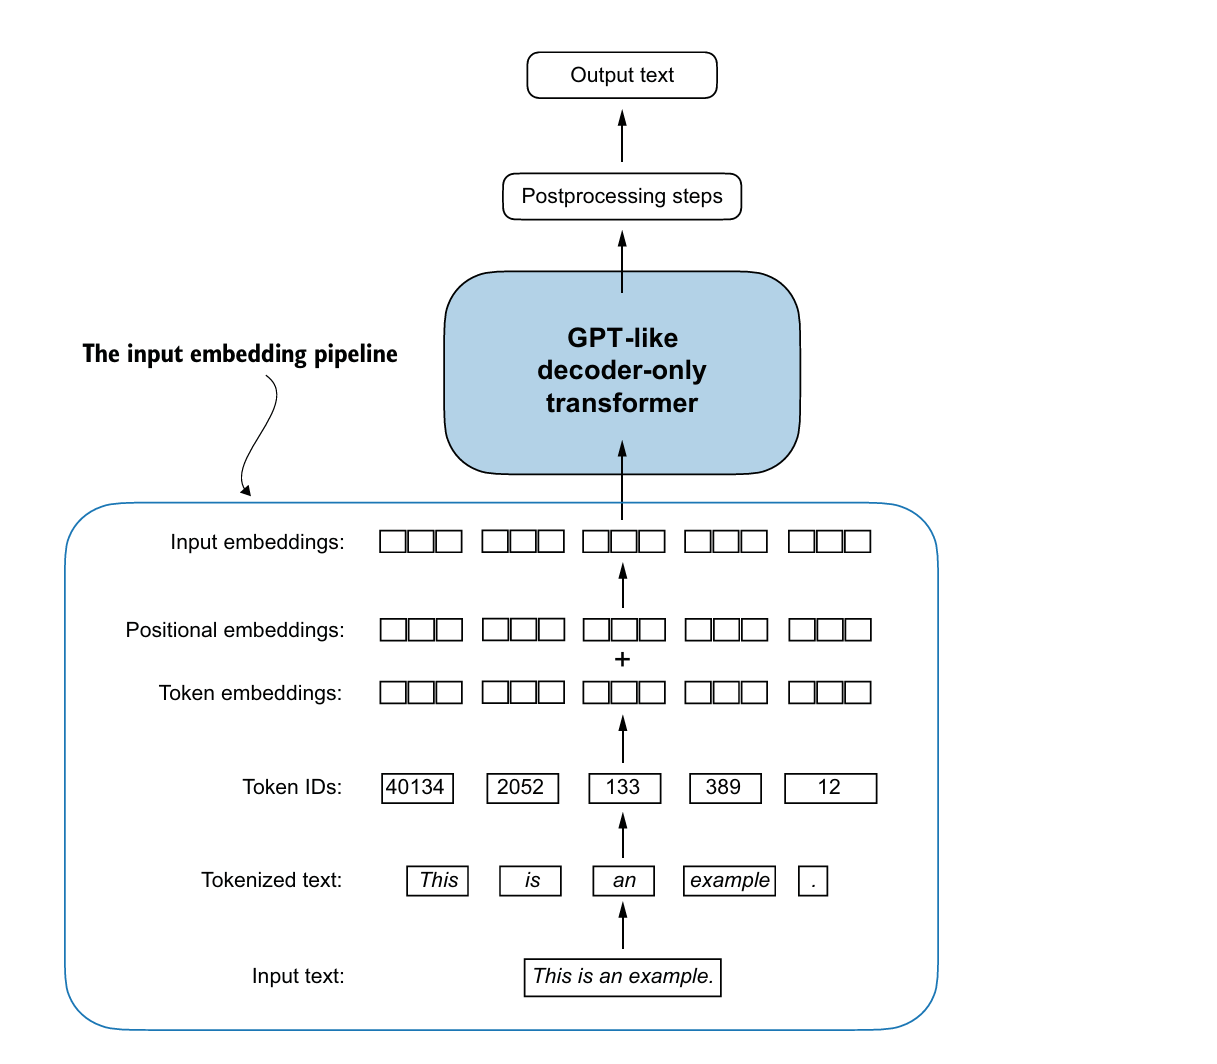